# Airbnb Listing Data Exploration (EDA)

## Purpose

This notebook explores the available Airbnb listing data before model training. The goals are to understand the dataset, inspect data quality, identify useful variables, and document which variables are part of the baseline preprocessing pipeline.


## Baseline and New-Host Prediction

The prediction use case is a **new host** listing. The model must therefore rely on information available when a listing is created, rather than on future host performance or post-booking activity.



In [85]:
import sys
from pathlib import Path
import pandas as pd

# Set the project root manually
project_root = Path("C:/Users/dinat/Υπολογιστής/Pfizer Masterclass/airbnb-price-prediction-app")
sys.path.append(str(project_root))

In [86]:
from backend.constants import cols_to_drop, neighbourhood_en

# Load raw listings data
raw_df = pd.read_csv(project_root / "data" / "listings.csv")

## Dataset Scope and Target

The raw listings file is loaded for exploration. The prediction target is `price`, which is cleaned from currency-formatted text before preprocessing.


The EDA should distinguish between:

- **Available variables:** columns present in the raw dataset.
- **Baseline variables:** columns retained or derived by the preprocessing pipeline.
- **Excluded variables:** identifiers, post-listing outcomes, duplicated information, and fields that are unavailable or unsafe for a new-host prediction.


The train/test split and all learned preprocessing steps must be fitted on the training data only. This keeps the baseline evaluation reproducible and prevents information from the test set from entering the model.

## Available Variables

The following inspection shows the complete raw schema. At this stage, the columns have not yet been classified as baseline model inputs.


Pay special attention to columns that represent host history, reviews, availability after listing, or identifiers. These can be useful for descriptive EDA, but they should not automatically be treated as valid predictors for a new host.

In [87]:
pd.set_option("display.max_rows", None)
raw_df.dtypes

Unnamed: 0                     int64
id                             int64
listing_url                   object
scrape_id                      int64
last_scraped                  object
name                          object
description                   object
neighborhood_overview         object
picture_url                   object
host_id                        int64
host_url                      object
host_name                     object
host_since                    object
host_location                 object
host_about                    object
host_response_time            object
host_response_rate            object
host_acceptance_rate          object
host_is_superhost             object
host_thumbnail_url            object
host_picture_url              object
host_neighbourhood            object
host_listings_count          float64
host_total_listings_count    float64
host_verifications            object
host_has_profile_pic          object
host_identity_verified        object
n

## Helpers

In [57]:
import ast
import numpy as np
import matplotlib.pyplot as plt

BLUE = "#4C78A8"

def missing_stats(cols):
    sub = raw_df[cols]
    return pd.DataFrame({"Missing": sub.isna().sum(), "Percentage": sub.isna().mean() * 100}).round(2)

def numeric_stats(cols):
    return raw_df[cols].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T.round(2)

def plot_categories(series, title, ylabel, top=None, height=6):
    pct = series.value_counts().div(len(raw_df)).mul(100)
    if top:
        pct = pct.head(top)
    ax = pct.plot.barh(color=BLUE, figsize=(10, height), width=0.7)
    ax.invert_yaxis()
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
    ax.set_xlim(0, pct.max() * 1.1)
    ax.set_xlabel("Listings (%)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=14, fontweight="bold", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

def plot_hist(series, title, xlabel, bins=40, log_x=False, log_y=False):
    data = series.dropna()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(data, bins=bins, color=BLUE, edgecolor="white", linewidth=0.8)
    if log_x:
        ax.set_xscale("log")
    if log_y:
        ax.set_yscale("log")
    median = data.median()
    ax.axvline(median, color="#E45756", linestyle="--", linewidth=1.5, label=f"Median: {median:.1f}")
    ax.legend(frameon=False)
    ax.set_title(title, fontsize=14, fontweight="bold", loc="left")
    ax.set_xlabel(xlabel + (" (log scale)" if log_x else ""))
    ax.set_ylabel("Listings" + (" (log scale)" if log_y else ""))
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


def plot_box(series, title, xlabel, log_x=False):
    fig, ax = plt.subplots(figsize=(10, 2.5))
    ax.boxplot(
        series.dropna(), vert=False, patch_artist=True,
        boxprops=dict(facecolor=BLUE, alpha=0.7),
        medianprops=dict(color="#E45756", linewidth=2),
        flierprops=dict(marker="o", markersize=3, alpha=0.4),
    )
    if log_x:
        ax.set_xscale("symlog")  # symlog keeps zeros plottable
    ax.set_yticks([])
    ax.set_title(title, fontsize=14, fontweight="bold", loc="left")
    ax.set_xlabel(xlabel + (" (log scale)" if log_x else ""))
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout()
    plt.show()

## Host Listings Counts

Inspect the distribution and upper tail of listings per host. This is useful context about the dataset, but host portfolio size may not be available for a genuinely new host and should not be assumed to be a valid baseline predictor.

,Missing,Percentage
host_listings_count,3,0.03


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
host_listings_count,9579.0,17.81,60.12,0.0,0.0,1.0,3.0,11.0,73.0,220.0,2095.0


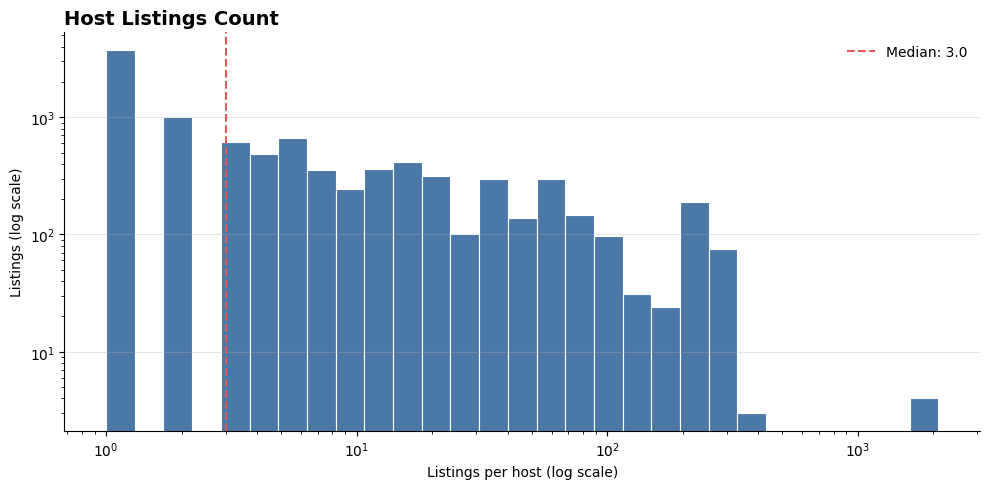

In [59]:
display(missing_stats(["host_listings_count"]))
display(numeric_stats(["host_listings_count"]))

data = raw_df["host_listings_count"].clip(lower=1)  # log bins cannot include 0
bins = np.logspace(0, np.log10(data.max()), 30)
plot_hist(data, "Host Listings Count", "Listings per host", bins=bins, log_x=True, log_y=True)

## Host Information

Host-related variables need special scrutiny because the model is intended for new hosts. Identifiers and historical host performance cannot generalize to a host with no prior activity and may introduce leakage if they describe information accumulated after listings were created.


The baseline preprocessing removes host identity, host profile, response, acceptance, superhost, and review-history fields. Variables retained for modeling must represent listing-time information and must be available for a new host at prediction time.

,Missing,Percentage
host_verifications,3,0.03


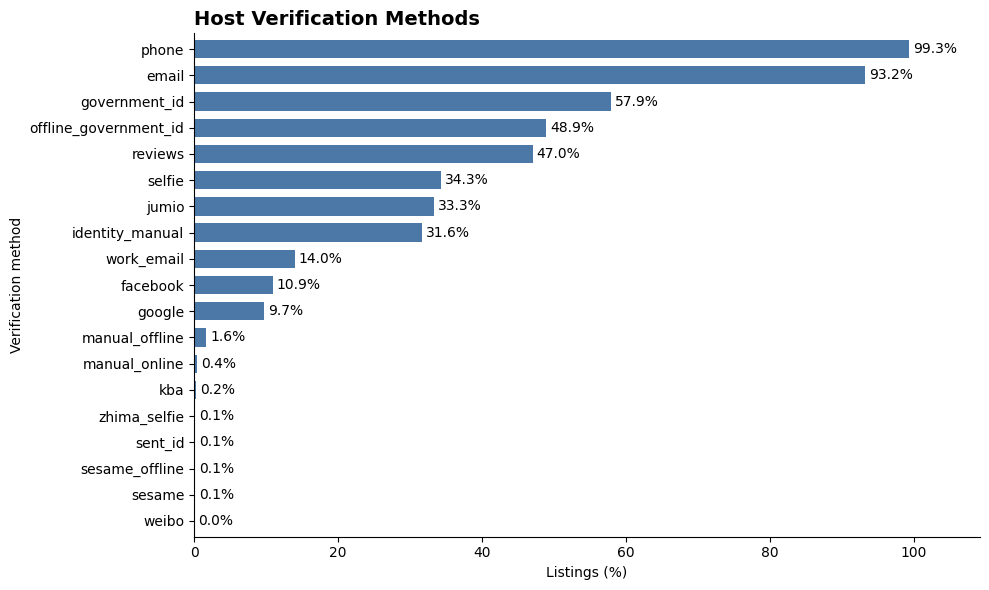

In [60]:
display(missing_stats(["host_verifications"]))

verification_methods = raw_df["host_verifications"].dropna().map(lambda v: set(ast.literal_eval(v))).explode()
plot_categories(verification_methods, "Host Verification Methods", "Verification method")

## Host Identity Verified

Compare the verified, unverified, and missing values. Treat this as a descriptive profile field: confirm that it is available at prediction time before including it in a new-host model.

,Missing,Percentage
host_identity_verified,3,0.03


,count,percentage
host_identity_verified,,
True,6928,72.30
False,2651,27.67
Missing,3,0.03


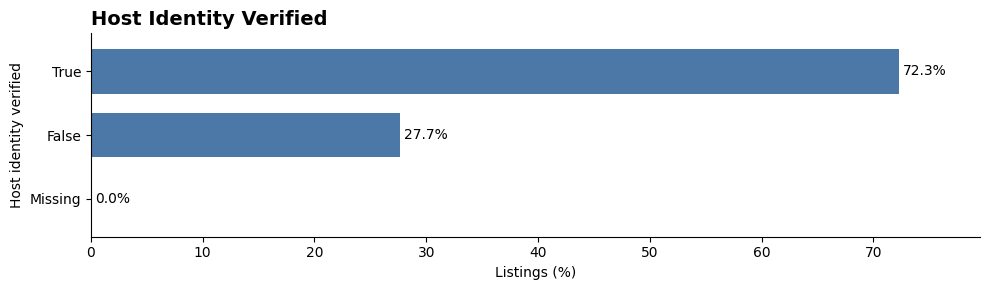

In [61]:
display(missing_stats(["host_identity_verified"]))
verified = raw_df["host_identity_verified"].map({"t": "True", "f": "False"}).fillna("Missing")
table = verified.value_counts().to_frame("count")
table["percentage"] = (table["count"] / len(raw_df) * 100).round(2)
display(table)
plot_categories(verified, "Host Identity Verified", "Host identity verified", height=3)

## Neighborhood

Neighborhood names provide a more interpretable view of listing location than raw coordinates. Review category frequency and missingness, and make sure any geographic grouping or rare-category handling is learned consistently from training data.

,Missing,Percentage
neighbourhood,0,0.0


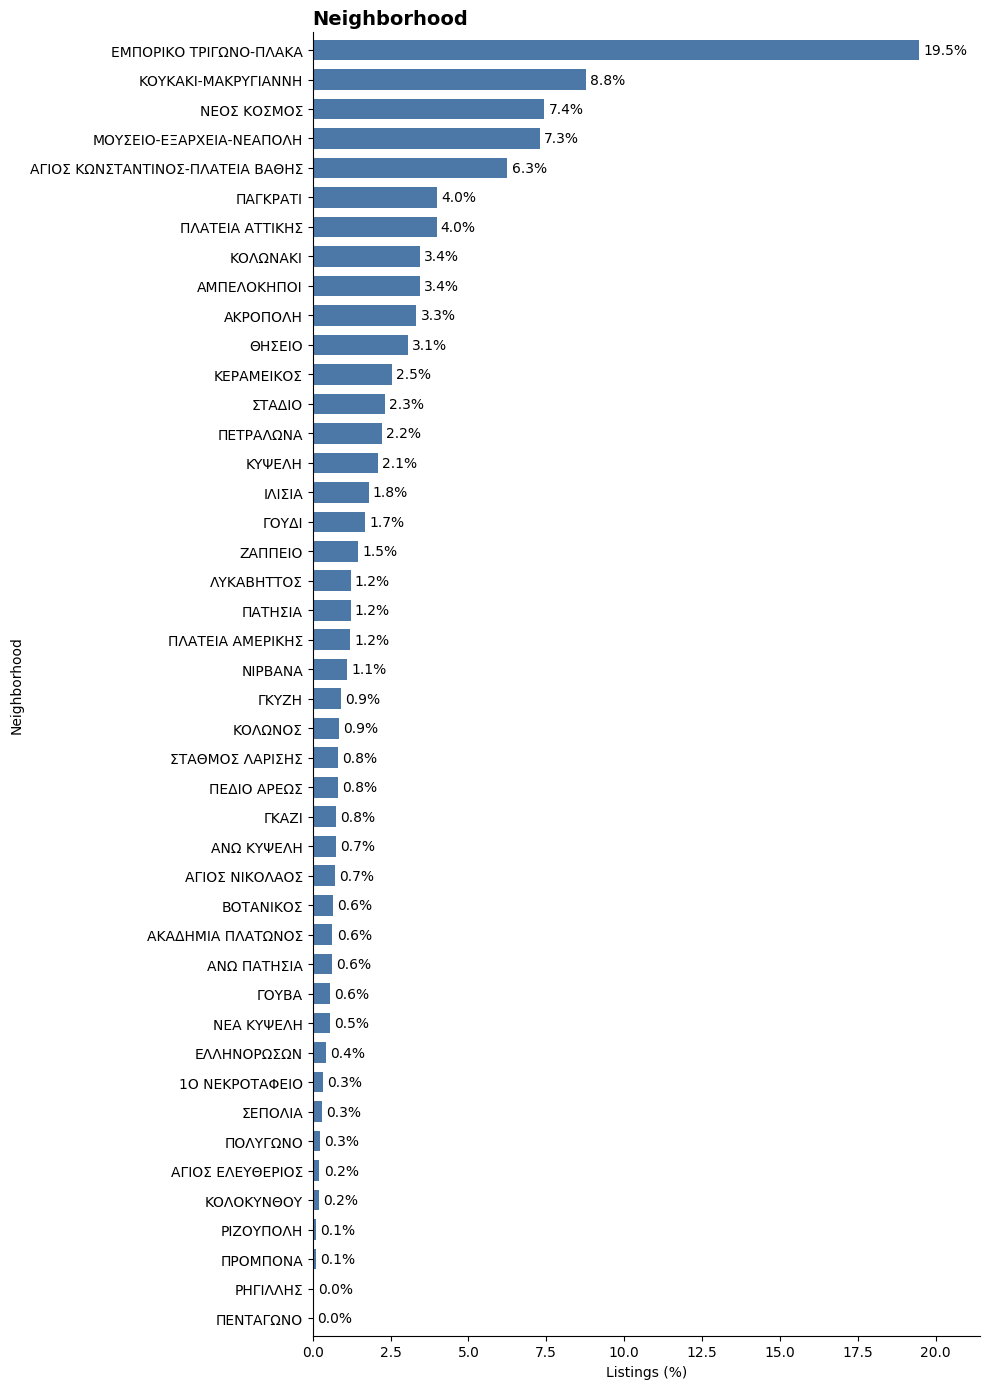

In [88]:
display(missing_stats(["neighbourhood"]))
plot_categories(raw_df["neighbourhood"].dropna(), "Neighborhood", "Neighborhood", height=14)

## Latitude & Longitude

Coordinates provide precise listing location and may capture local price differences. Review the ranges for invalid values and consider whether this level of geographic detail is appropriate for the intended prediction and privacy requirements.

In [63]:
cols = ["latitude", "longitude"]
display(missing_stats(cols))
display(numeric_stats(cols))

,Missing,Percentage
latitude,0,0.0
longitude,0,0.0


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
latitude,9582.0,37.98,0.01,37.95,37.96,37.97,37.98,37.99,38.00,38.02,38.03
longitude,9582.0,23.73,0.01,23.70,23.71,23.72,23.73,23.74,23.76,23.77,23.78


## Property Type & Room Type

Compare the frequency and missingness of these categorical descriptions. They capture different aspects of an accommodation, so check their category granularity and rare values before choosing an encoding strategy.

,Missing,Percentage
property_type,0,0.0
room_type,0,0.0


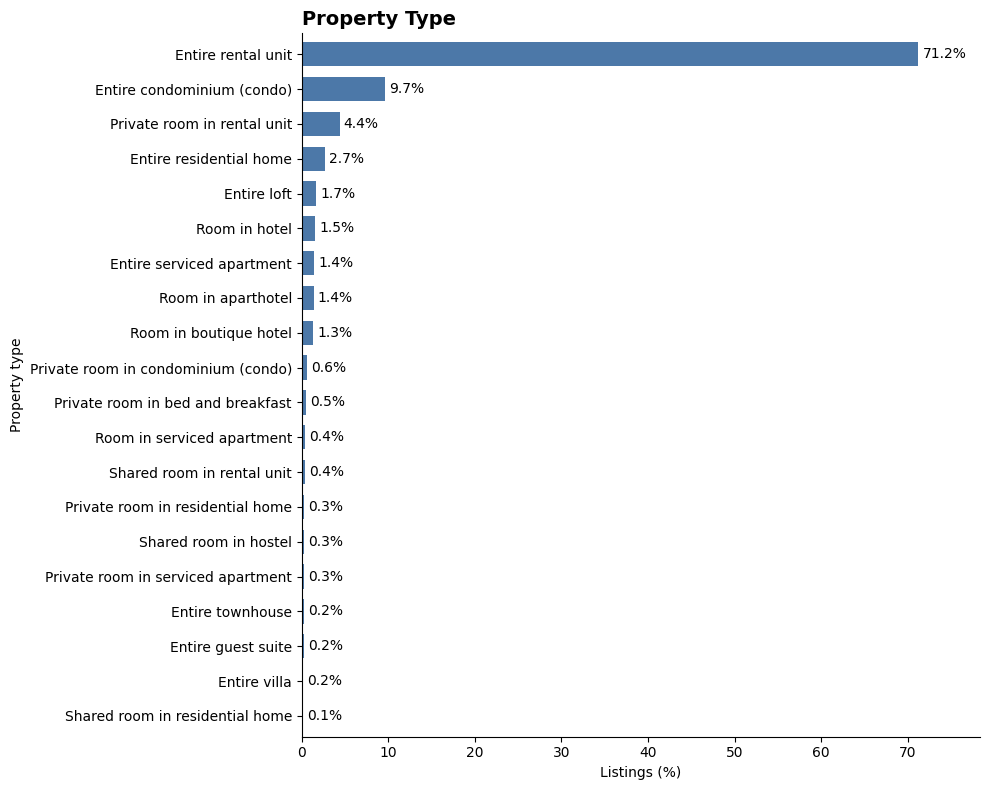

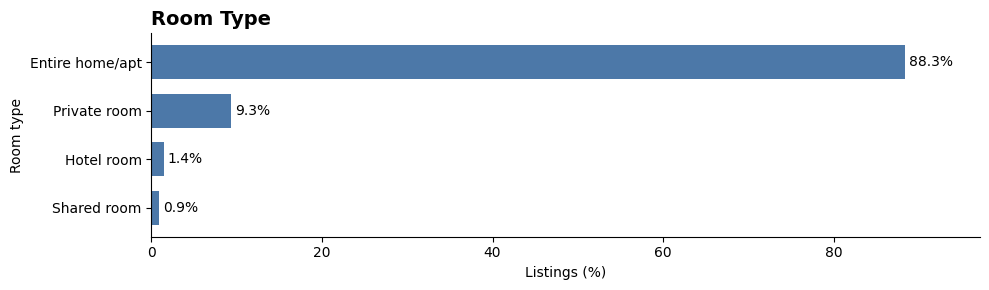

In [64]:
display(missing_stats(["property_type", "room_type"]))
plot_categories(raw_df["property_type"].dropna(), "Property Type", "Property type", top=20, height=8)
plot_categories(raw_df["room_type"].dropna(), "Room Type", "Room type", height=3)

## Accommodates, Bathrooms, Bedrooms & Beds

These numeric fields describe listing capacity and layout. Use the summaries and box plots to check missingness, implausible values, and skew; the section currently summarizes accommodates, bedrooms, and beds, while bathroom information is explored separately below.

,Missing,Percentage
accommodates,0,0.00
bedrooms,813,8.48
beds,68,0.71


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
accommodates,9582.0,3.83,1.96,1.0,2.0,2.0,4.0,4.0,7.0,11.19,16.0
bedrooms,8769.0,1.49,0.80,1.0,1.0,1.0,1.0,2.0,3.0,4.00,12.0
beds,9514.0,2.10,1.55,0.0,1.0,1.0,2.0,3.0,4.0,7.00,44.0


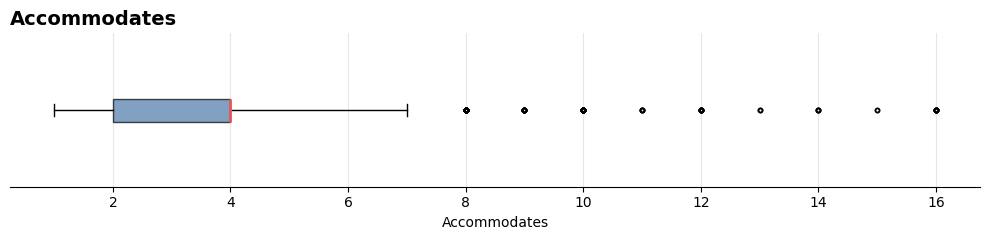

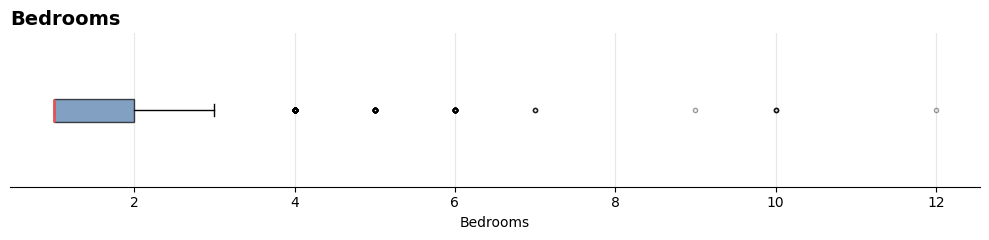

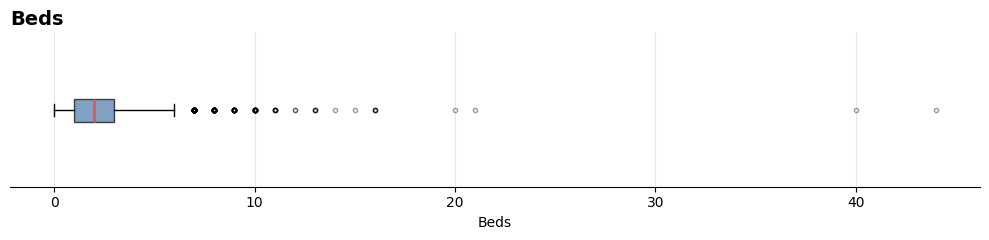

In [66]:
cols = ["accommodates", "bedrooms", "beds"]
display(missing_stats(cols))
display(numeric_stats(cols))
for col in cols:
    plot_box(raw_df[col], col.capitalize(), col.capitalize())

## Bathrooms Text

This field combines bathroom quantity with room-sharing labels, so it is not purely numeric. Review common values and missingness before deciding how to parse or encode it.

,Missing,Percentage
bathrooms_text,10,0.1


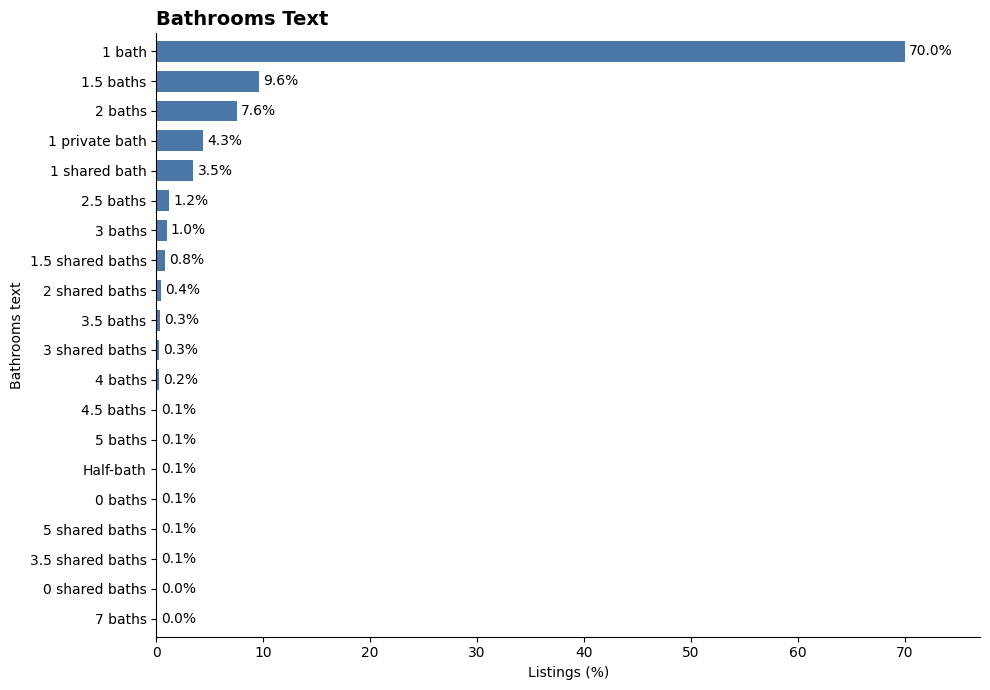

In [67]:
display(missing_stats(["bathrooms_text"]))
plot_categories(raw_df["bathrooms_text"].dropna(), "Bathrooms Text", "Bathrooms text", top=20, height=7)

## Amenities

The cell expands each listing's amenity list into individual values and plots the most frequent items. Frequency is useful for prioritizing features, but rare amenities and list parsing should be handled consistently during preprocessing.

,Missing,Percentage
amenities,0,0.0


Unique amenities: 957


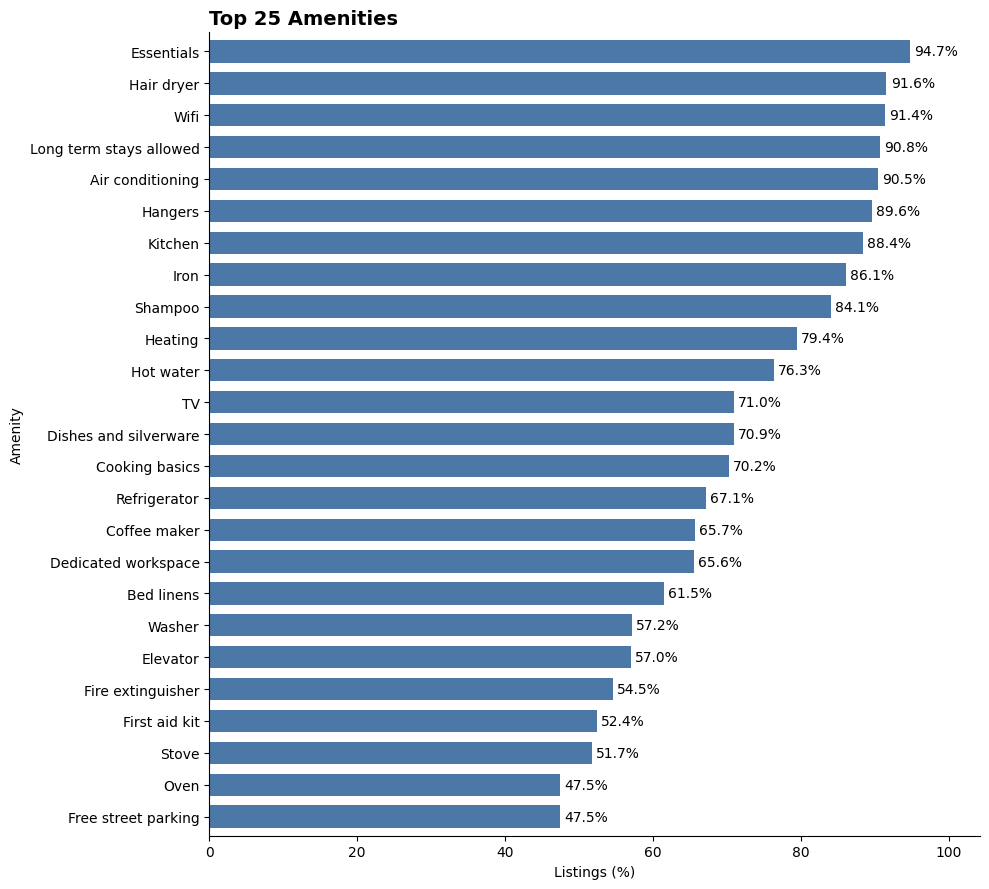

In [68]:
display(missing_stats(["amenities"]))

amenities = raw_df["amenities"].dropna().map(lambda v: set(ast.literal_eval(v))).explode()
print(f"Unique amenities: {amenities.nunique()}")
plot_categories(amenities, "Top 25 Amenities", "Amenity", top=25, height=9)

## Price

Price is the prediction target. The code removes currency symbols and thousands separators before summarizing and plotting its distribution; inspect the tail because extreme values can affect model fit and should be handled using training data only.

,Missing,Percentage
price,0,0.0


,price
count,9582.00
mean,83.44
std,299.56
min,9.00
5%,23.00
25%,36.00
50%,50.00
75%,80.00
95%,176.95
99%,440.57


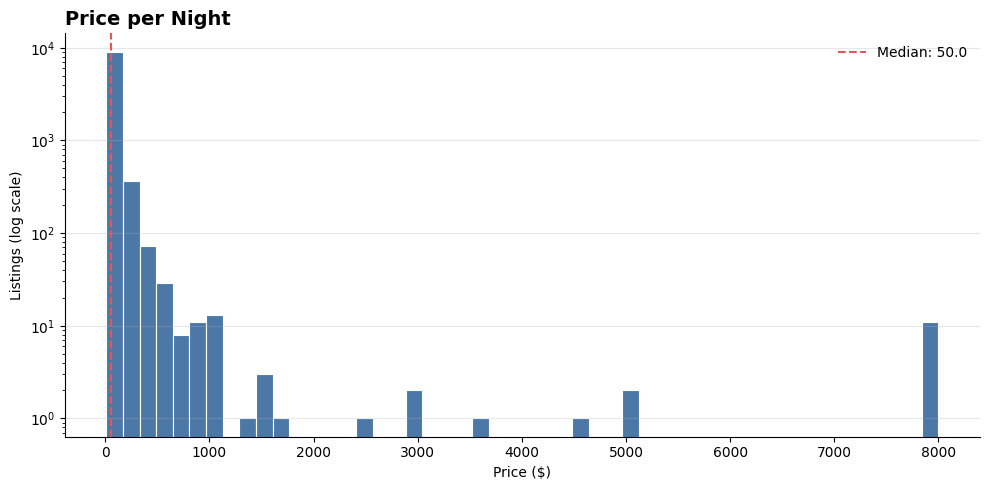

In [70]:
price = raw_df["price"].str.replace(r"[$,]", "", regex=True).astype(float)
display(missing_stats(["price"]))
display(price.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2).to_frame("price"))
plot_hist(price, "Price per Night", "Price ($)", bins=50, log_y=True)

## Minimum & Maximum Nights

These booking-rule fields can be strongly skewed, which is why the plots use a symmetric logarithmic axis that can still display zero. Check unusually large values and confirm these settings are available at the intended prediction time.

,Missing,Percentage
minimum_nights,0,0.0
maximum_nights,0,0.0


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
minimum_nights,9582.0,3.27,19.92,1.0,1.0,1.0,2.0,2.0,5.0,30.0,1000.0
maximum_nights,9582.0,1789.78,102151.45,1.0,15.0,90.0,1125.0,1125.0,1125.0,1125.0,9999999.0


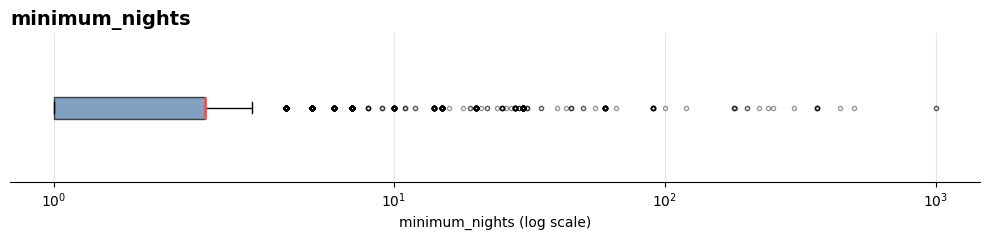

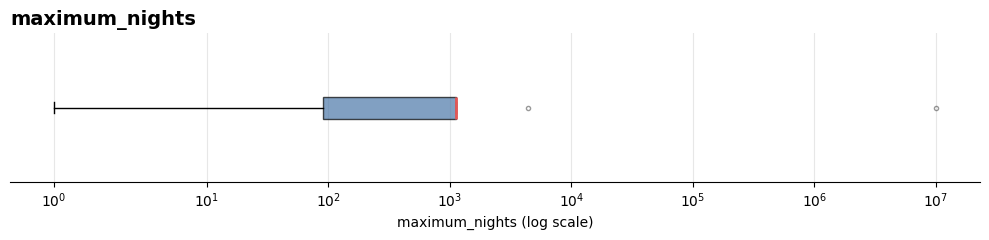

In [74]:
cols = ["minimum_nights", "maximum_nights"]
display(missing_stats(cols))
display(numeric_stats(cols))
for col in cols:
    plot_box(raw_df[col], col, col, log_x=True)

## Availability

Availability windows describe calendar state and may change over time. Inspect their distributions, but verify that these values reflect information available when the prediction is made; avoid using a later snapshot as if it were known at listing creation.

,Missing,Percentage
availability_30,0,0.0
availability_60,0,0.0
availability_90,0,0.0
availability_365,0,0.0


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
availability_30,9582.0,13.15,11.30,0.0,0.0,0.00,13.0,24.0,30.0,30.0,30.0
availability_60,9582.0,32.59,22.99,0.0,0.0,1.25,40.0,54.0,60.0,60.0,60.0
availability_90,9582.0,53.23,33.77,0.0,0.0,22.00,66.0,83.0,90.0,90.0,90.0
availability_365,9582.0,230.26,130.26,0.0,0.0,117.00,283.0,350.0,365.0,365.0,365.0


,Missing,Percentage
availability_30,0,0.0
availability_60,0,0.0
availability_90,0,0.0
availability_365,0,0.0


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
availability_30,9582.0,13.15,11.30,0.0,0.0,0.00,13.0,24.0,30.0,30.0,30.0
availability_60,9582.0,32.59,22.99,0.0,0.0,1.25,40.0,54.0,60.0,60.0,60.0
availability_90,9582.0,53.23,33.77,0.0,0.0,22.00,66.0,83.0,90.0,90.0,90.0
availability_365,9582.0,230.26,130.26,0.0,0.0,117.00,283.0,350.0,365.0,365.0,365.0


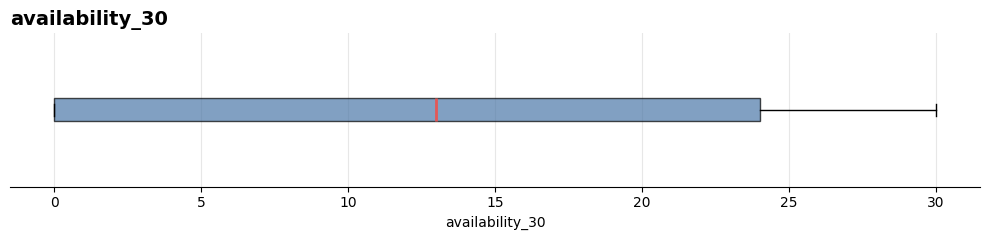

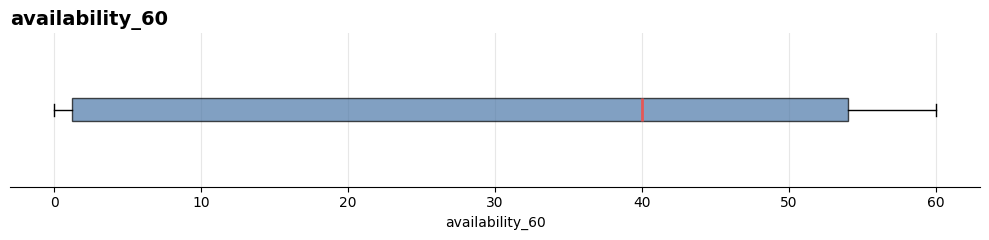

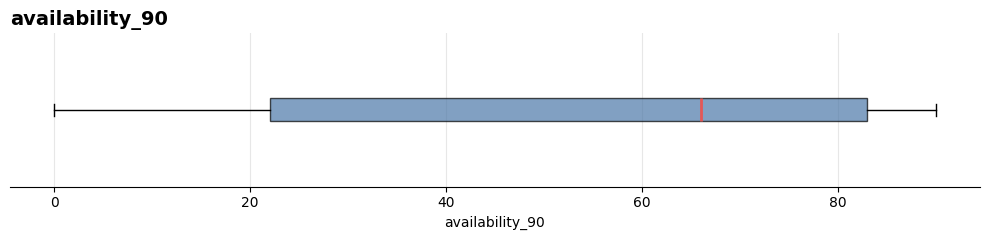

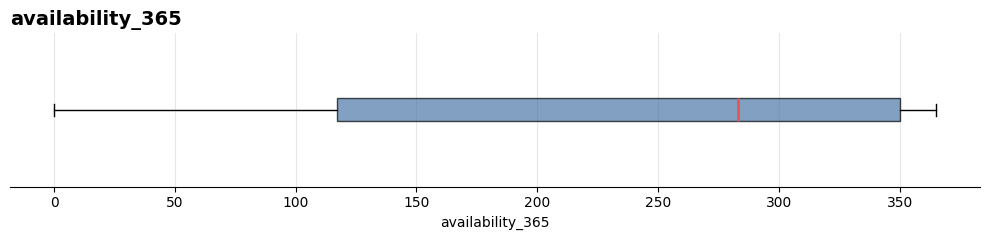

In [76]:
cols = ["availability_30", "availability_60", "availability_90", "availability_365"]
display(missing_stats(cols))
display(numeric_stats(cols))

cols = ["availability_30", "availability_60", "availability_90", "availability_365"]
display(missing_stats(cols))
display(numeric_stats(cols))
for col in cols:
    plot_box(raw_df[col], col, col)

## Instant Bookable

This binary setting indicates whether a listing can be booked instantly. The table includes missing values as a separate category so the distribution is visible before preprocessing.

,Missing,Percentage
instant_bookable,0,0.0


,count,percentage
instant_bookable,,
True,6574,68.61
False,3008,31.39


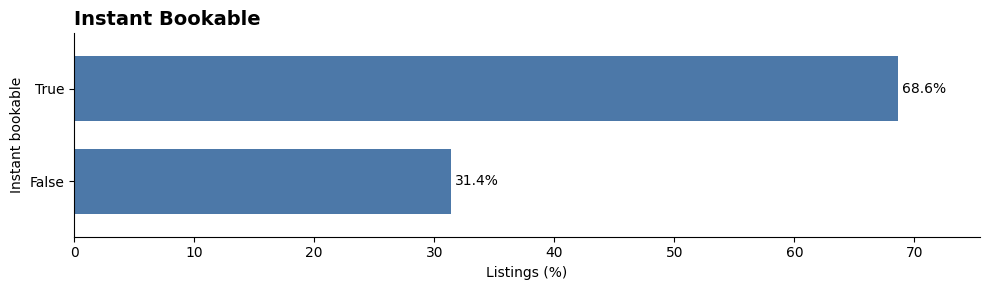

In [78]:
display(missing_stats(["instant_bookable"]))
instant = raw_df["instant_bookable"].map({"t": "True", "f": "False"}).fillna("Missing")
table = instant.value_counts().to_frame("count")
table["percentage"] = (table["count"] / len(raw_df) * 100).round(2)
display(table)
plot_categories(instant, "Instant Bookable", "Instant bookable", height=3)

## Missingness Across Candidate Features

This final plot compares missing-value percentages for the selected candidate columns. It describes data completeness only; it does not choose an imputation method or establish that every listed field belongs in the baseline model.

,Missing,Percentage
bedrooms,813,8.48
beds,68,0.71
bathrooms_text,10,0.10
host_verifications,3,0.03
host_listings_count,3,0.03
host_identity_verified,3,0.03
longitude,0,0.00
property_type,0,0.00
room_type,0,0.00
accommodates,0,0.00


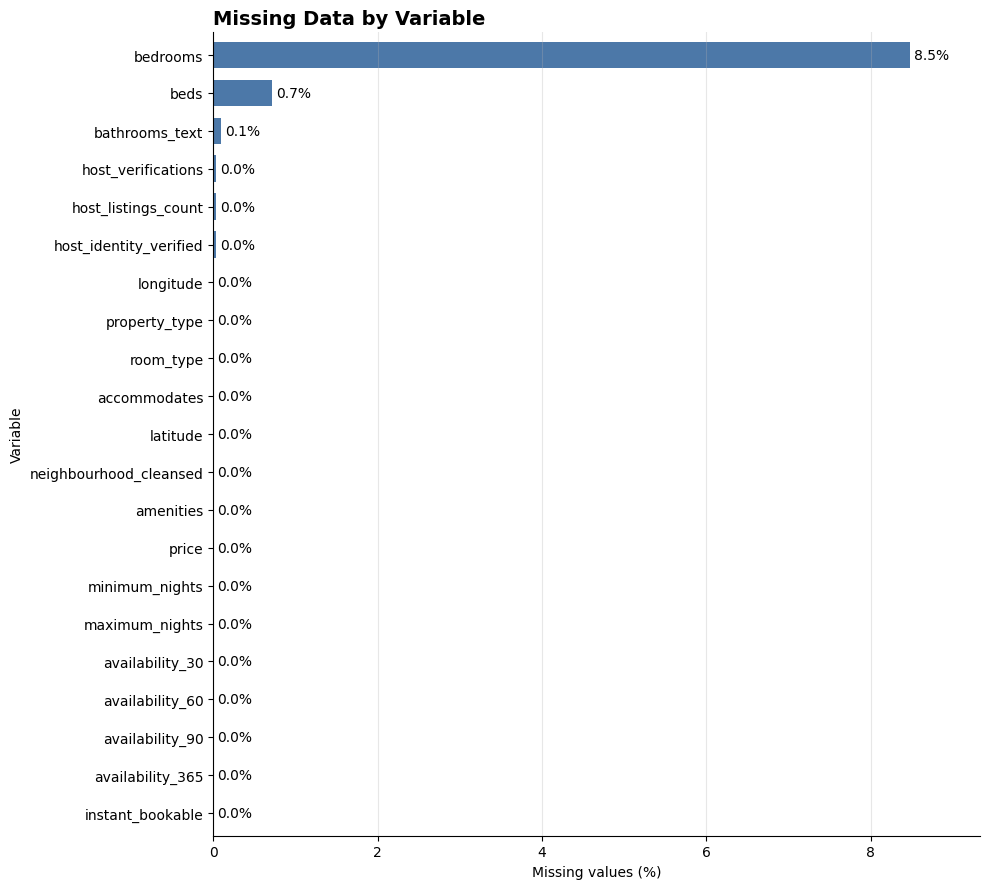

In [83]:
selected_cols = [
    "host_listings_count", "host_verifications", "host_identity_verified",
    "neighbourhood_cleansed", "latitude", "longitude",
    "property_type", "room_type", "accommodates", "bathrooms_text",
    "bedrooms", "beds", "amenities", "price",
    "minimum_nights", "maximum_nights",
    "availability_30", "availability_60", "availability_90", "availability_365",
     "instant_bookable",
]

missing_df = missing_stats(selected_cols).sort_values("Percentage", ascending=False)
display(missing_df)

ax = missing_df["Percentage"].plot.barh(color=BLUE, figsize=(10, 9), width=0.7)
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xlim(0, max(missing_df["Percentage"].max() * 1.1, 1))  # avoid a zero-width axis when nothing is missing
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Variable")
ax.set_title("Missing Data by Variable", fontsize=14, fontweight="bold", loc="left")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()